# Task 3 — Is one acquisition channel better than another?

**Business question:** UA spends across `organic`, `paid_social`, and `paid_video`. Compare player quality using one engagement measure and one revenue measure, quantify uncertainty, and investigate whether an apparent difference is genuine or an artefact of channel composition.

This notebook is intentionally an **analysis runner**, following the same pattern as Task 2: the analytical SQL lives in `sql/task-3/`, while the notebook executes those SQL files, generates tables/charts, and records the interpretation.

## 1. Setup

The notebook creates `analysis.duckdb` from the real CSV files bundled in this package, then executes the linked SQL files.

**Observation windows**
- 7-day engagement: installs through 2026-03-31.
- 30-day revenue: installs through 2026-03-31.

This ensures complete observation windows.

In [42]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent
SQL_DIR = PROJECT / "sql" / "task-3"
OUTPUT_DIR = PROJECT / "output" / "task-3"
CHART_DIR = OUTPUT_DIR / "charts"
TABLE_DIR = OUTPUT_DIR / "tables"

CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

DB_PATH = PROJECT / "analysis.duckdb"
con = duckdb.connect(str(DB_PATH))

print("Project:", PROJECT)
print("Database:", DB_PATH)
print("SQL directory:", SQL_DIR)
print("Output directory:", OUTPUT_DIR)

Project: v:\2026\Analytics Intern Assignment
Database: v:\2026\Analytics Intern Assignment\analysis.duckdb
SQL directory: v:\2026\Analytics Intern Assignment\sql\task-3
Output directory: v:\2026\Analytics Intern Assignment\output\task-3


## 2. Load the real CSV data through the setup SQL

In [43]:
setup_sql = (SQL_DIR / "00_setup.sql").read_text()
con.execute(setup_sql)

print(con.execute("SHOW TABLES").df())

             name
0         ad_view
1  currency_spend
2      player_day
3  player_profile
4        purchase


## 3. Data-quality checks relevant to Task 3

In [44]:
dq = con.execute((SQL_DIR / "3e_quality_checks.sql").read_text()).df()
dq.to_csv(TABLE_DIR / "data_quality_checks.csv", index=False)
display(dq)

,check_name,issue_count
0,duplicate player_profile device_id,0
1,duplicate player_day player-date key,0
2,purchase IDs appearing more than once,122
3,purchases before recorded install,114
4,purchase rows outside assignment window,0


### Quality-treatment decisions

- Complete observation windows are used so newer installs are not disadvantaged.
- Duplicate purchase IDs are **flagged, not blindly deduplicated**.
- Purchases before recorded install are retained in the primary reproducible revenue calculation because the task is based on recorded telemetry; the issue is explicitly reported.
- Revenue means in-app purchases only.

## 4. Acquisition-channel population

In [45]:
population = con.execute((SQL_DIR / "3a_channel_population.sql").read_text()).df()
population.to_csv(TABLE_DIR / "channel_population.csv", index=False)
display(population)

,acquisition_channel,players
0,organic,20159
1,paid_social,17857
2,paid_video,15473


## 5. First-7-day engagement

In [46]:
engagement = con.execute((SQL_DIR / "3b_engagement.sql").read_text()).df()
engagement.to_csv(TABLE_DIR / "engagement_player_level.csv", index=False)

engagement_summary = engagement.groupby("acquisition_channel").agg(
    players=("device_id","size"),
    avg_playtime_7d=("playtime_7d","mean"),
    median_playtime_7d=("playtime_7d","median"),
    avg_sessions_7d=("sessions_7d","mean"),
    avg_active_days_7d=("active_days_7d","mean")
).reset_index()

engagement_summary.to_csv(TABLE_DIR / "engagement_summary.csv", index=False)
display(engagement_summary.round(3))

,acquisition_channel,players,avg_playtime_7d,median_playtime_7d,avg_sessions_7d,avg_active_days_7d
0,organic,20159,37.288,20.4,6.676,1.803
1,paid_social,17857,34.946,19.9,6.411,1.777
2,paid_video,15473,44.752,33.5,8.269,2.295


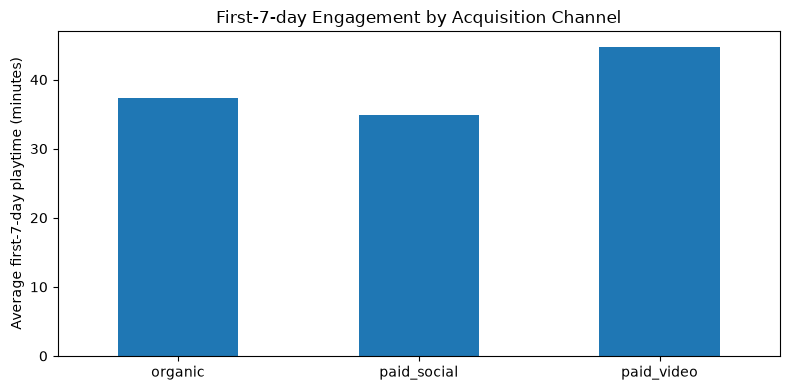

In [47]:
ax = engagement_summary.plot(
    x="acquisition_channel", y="avg_playtime_7d",
    kind="bar", legend=False, figsize=(8,4)
)
ax.set_ylabel("Average first-7-day playtime (minutes)")
ax.set_xlabel("")
ax.set_title("First-7-day Engagement by Acquisition Channel")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(CHART_DIR / "engagement_by_channel.png", dpi=180)
plt.show()

## 6. First-30-day revenue

In [48]:
revenue = con.execute((SQL_DIR / "3c_revenue.sql").read_text()).df()
revenue.to_csv(TABLE_DIR / "revenue_player_level.csv", index=False)

revenue_summary = revenue.groupby("acquisition_channel").agg(
    players=("device_id","size"),
    avg_revenue_30d=("revenue_30d","mean"),
    median_revenue_30d=("revenue_30d","median"),
    payer_conversion_30d=("revenue_30d", lambda s: (s > 0).mean())
).reset_index()

revenue_summary.to_csv(TABLE_DIR / "revenue_summary.csv", index=False)
display(revenue_summary.round(4))

,acquisition_channel,players,avg_revenue_30d,median_revenue_30d,payer_conversion_30d
0,organic,20159,1.6185,0.0,0.0874
1,paid_social,17857,1.4793,0.0,0.0868
2,paid_video,15473,1.2995,0.0,0.0749


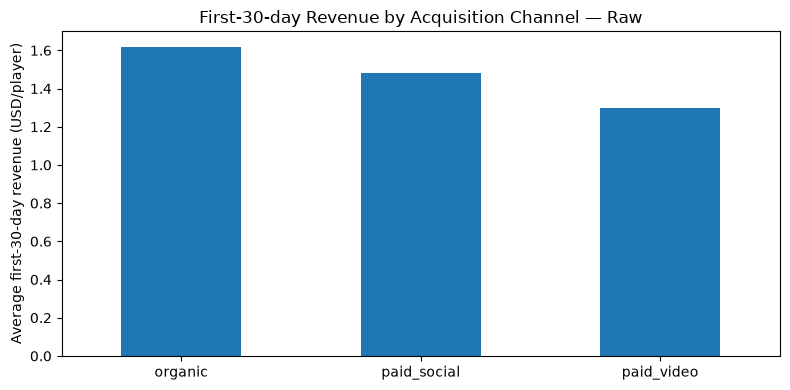

In [49]:
ax = revenue_summary.plot(
    x="acquisition_channel", y="avg_revenue_30d",
    kind="bar", legend=False, figsize=(8,4)
)
ax.set_ylabel("Average first-30-day revenue (USD/player)")
ax.set_xlabel("")
ax.set_title("First-30-day Revenue by Acquisition Channel — Raw")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(CHART_DIR / "revenue_by_channel_raw.png", dpi=180)
plt.show()

## 7. Channel mix check

In [50]:
mix = con.execute((SQL_DIR / "3d_channel_mix.sql").read_text()).df()
mix.to_csv(TABLE_DIR / "channel_mix_detail.csv", index=False)

tier_mix = (
    mix.groupby(["acquisition_channel","country_tier"])["players"].sum()
    .groupby(level=0).transform(lambda s: s/s.sum())
    .reset_index(name="share")
)
month_mix = (
    mix.groupby(["acquisition_channel","install_month"])["players"].sum()
    .groupby(level=0).transform(lambda s: s/s.sum())
    .reset_index(name="share")
)

tier_mix.to_csv(TABLE_DIR / "country_tier_mix.csv", index=False)
month_mix.to_csv(TABLE_DIR / "install_month_mix.csv", index=False)

display(tier_mix.pivot(index="country_tier", columns="acquisition_channel", values="share").round(3))
display(month_mix.pivot(index="install_month", columns="acquisition_channel", values="share").round(3))

acquisition_channel,organic,paid_social,paid_video
country_tier,,,
1,0.338,0.345,0.110
2,0.257,0.253,0.085
3,0.222,0.218,0.152
4,0.183,0.184,0.653


acquisition_channel,organic,paid_social,paid_video
install_month,,,
2026-01-01,0.347,0.333,0.114
2026-02-01,0.310,0.320,0.136
2026-03-01,0.343,0.347,0.750


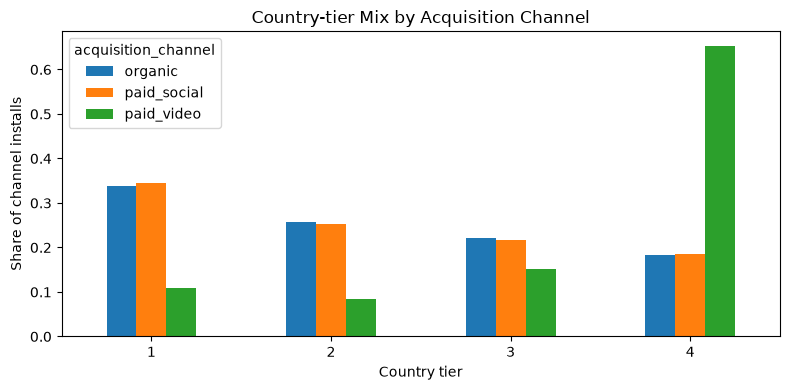

In [51]:
tier_plot = tier_mix.pivot(
    index="country_tier", columns="acquisition_channel", values="share"
)
ax = tier_plot.plot(kind="bar", figsize=(8,4))
ax.set_ylabel("Share of channel installs")
ax.set_xlabel("Country tier")
ax.set_title("Country-tier Mix by Acquisition Channel")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(CHART_DIR / "country_tier_mix.png", dpi=180)
plt.show()

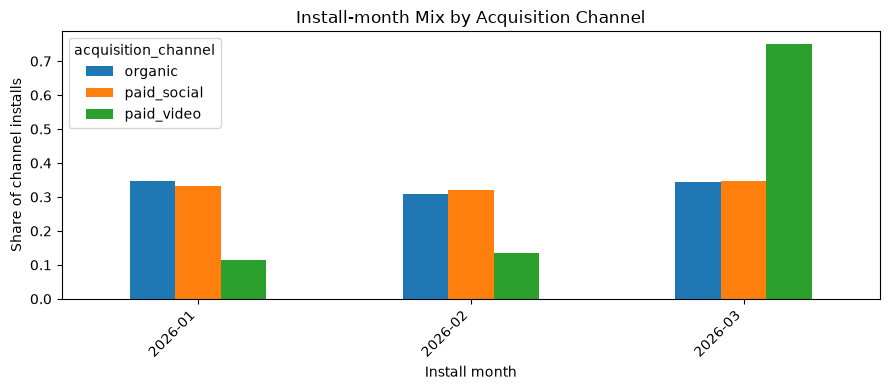

In [52]:
# Clean install month for plotting
month_mix["install_month"] = pd.to_datetime(month_mix["install_month"])
month_mix["install_month_label"] = month_mix["install_month"].dt.strftime("%Y-%m")

# Pivot for chart
month_plot = month_mix.pivot(
    index="install_month_label",
    columns="acquisition_channel",
    values="share"
)

# Plot
ax = month_plot.plot(kind="bar", figsize=(9, 4))

ax.set_ylabel("Share of channel installs")
ax.set_xlabel("Install month")
ax.set_title("Install-month Mix by Acquisition Channel")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "install_month_mix.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## 8. Confidence intervals and statistical significance

The headline comparison is **organic vs paid_video**.

Revenue is highly skewed, so a player-level bootstrap is used rather than relying only on a normal-theory interval.

In [54]:
# ============================================================
# TASK 3 — Confidence Interval + P-value + Significance
# Common cohort: Jan 1–Mar 31, 2026
# Contrast: Organic - Paid Video
# ============================================================

import numpy as np
import pandas as pd


START_DATE = pd.Timestamp("2026-01-01")
END_DATE   = pd.Timestamp("2026-03-31")


# ============================================================
# 1. Common install cohort
# ============================================================

engagement = engagement.copy()
revenue = revenue.copy()

engagement["install_date"] = pd.to_datetime(
    engagement["install_date"]
)

revenue["install_date"] = pd.to_datetime(
    revenue["install_date"]
)

engagement = engagement[
    (engagement["install_date"] >= START_DATE) &
    (engagement["install_date"] <= END_DATE)
].copy()

revenue = revenue[
    (revenue["install_date"] >= START_DATE) &
    (revenue["install_date"] <= END_DATE)
].copy()


# ============================================================
# 2. Bootstrap 95% CI + permutation p-value
# ============================================================

def compare_channels(a, b, n_boot=3000, n_perm=3000, seed=42):

    rng = np.random.default_rng(seed)

    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    # --------------------------------------------------------
    # Observed difference
    # Organic - Paid Video
    # --------------------------------------------------------

    observed_difference = a.mean() - b.mean()


    # --------------------------------------------------------
    # Bootstrap confidence interval
    # --------------------------------------------------------

    boot_diffs = np.empty(n_boot)

    for i in range(n_boot):

        a_boot = rng.choice(
            a,
            size=len(a),
            replace=True
        )

        b_boot = rng.choice(
            b,
            size=len(b),
            replace=True
        )

        boot_diffs[i] = (
            a_boot.mean() -
            b_boot.mean()
        )

    ci_low, ci_high = np.quantile(
        boot_diffs,
        [0.025, 0.975]
    )


    # --------------------------------------------------------
    # Permutation test for p-value
    #
    # Null hypothesis:
    # Organic mean = Paid Video mean
    # --------------------------------------------------------

    combined = np.concatenate([a, b])

    n_a = len(a)

    perm_diffs = np.empty(n_perm)

    for i in range(n_perm):

        shuffled = rng.permutation(combined)

        perm_a = shuffled[:n_a]
        perm_b = shuffled[n_a:]

        perm_diffs[i] = (
            perm_a.mean() -
            perm_b.mean()
        )


    # Two-sided p-value
    p_value = (
        np.sum(
            np.abs(perm_diffs)
            >= abs(observed_difference)
        ) + 1
    ) / (n_perm + 1)


    # --------------------------------------------------------
    # Statistical significance
    # --------------------------------------------------------

    statistically_significant = p_value < 0.05


    return (
        observed_difference,
        ci_low,
        ci_high,
        p_value,
        statistically_significant
    )


# ============================================================
# 3. RAW — 7-day playtime
# ============================================================

eng_raw = compare_channels(

    engagement.loc[
        engagement["acquisition_channel"] == "organic",
        "playtime_7d"
    ],

    engagement.loc[
        engagement["acquisition_channel"] == "paid_video",
        "playtime_7d"
    ]
)


# ============================================================
# 4. RAW — 30-day revenue
# ============================================================

rev_raw = compare_channels(

    revenue.loc[
        revenue["acquisition_channel"] == "organic",
        "revenue_30d"
    ],

    revenue.loc[
        revenue["acquisition_channel"] == "paid_video",
        "revenue_30d"
    ]
)


# ============================================================
# 5. Install month
# ============================================================

revenue["install_month"] = (
    pd.to_datetime(
        revenue["install_date"]
    )
    .dt.to_period("M")
    .astype(str)
)


# ============================================================
# 6. Standardized revenue comparison
# ============================================================

strata = [
    "country_tier",
    "install_month"
]


# Pooled composition
pooled_weights = (
    revenue
    .groupby(strata)
    .size()
)

pooled_weights = (
    pooled_weights /
    pooled_weights.sum()
)


# Values within each channel and stratum
values = {
    channel: {
        key: group["revenue_30d"].to_numpy()
        for key, group in revenue[
            revenue["acquisition_channel"] == channel
        ].groupby(strata)
    }
    for channel in ["organic", "paid_video"]
}


# Only strata present in both channels
common = [
    key
    for key in pooled_weights.index
    if key in values["organic"]
    and key in values["paid_video"]
]


# Normalize weights
weights = pooled_weights.loc[common]
weights = weights / weights.sum()


# ============================================================
# 7. Bootstrap standardized difference
# ============================================================

rng = np.random.default_rng(42)

n_boot = 3000
n_perm = 3000

boot_diffs = np.empty(n_boot)

for i in range(n_boot):

    organic_mean = 0.0
    video_mean = 0.0

    for key, weight in weights.items():

        organic_sample = rng.choice(
            values["organic"][key],
            size=len(values["organic"][key]),
            replace=True
        )

        video_sample = rng.choice(
            values["paid_video"][key],
            size=len(values["paid_video"][key]),
            replace=True
        )

        organic_mean += (
            weight *
            organic_sample.mean()
        )

        video_mean += (
            weight *
            video_sample.mean()
        )

    boot_diffs[i] = (
        organic_mean -
        video_mean
    )


# 95% CI
std_ci_low, std_ci_high = np.quantile(
    boot_diffs,
    [0.025, 0.975]
)


# Standardized point estimate
organic_point = sum(
    weights.loc[key] *
    values["organic"][key].mean()
    for key in common
)

video_point = sum(
    weights.loc[key] *
    values["paid_video"][key].mean()
    for key in common
)

std_difference = (
    organic_point -
    video_point
)


# ============================================================
# 8. Permutation test for standardized comparison
# ============================================================

# For each stratum, pool both channels and randomly
# reassign observations while preserving the stratum size.

perm_diffs = np.empty(n_perm)

for i in range(n_perm):

    organic_perm = 0.0
    video_perm = 0.0

    for key, weight in weights.items():

        organic_values = values["organic"][key]
        video_values = values["paid_video"][key]

        combined = np.concatenate([
            organic_values,
            video_values
        ])

        shuffled = rng.permutation(combined)

        n_organic = len(organic_values)

        perm_organic = shuffled[:n_organic]
        perm_video = shuffled[n_organic:]

        organic_perm += (
            weight *
            perm_organic.mean()
        )

        video_perm += (
            weight *
            perm_video.mean()
        )

    perm_diffs[i] = (
        organic_perm -
        video_perm
    )


# Two-sided p-value
std_p_value = (
    np.sum(
        np.abs(perm_diffs)
        >= abs(std_difference)
    ) + 1
) / (n_perm + 1)


std_significant = (
    std_p_value < 0.05
)


# ============================================================
# 9. Final results table
# ============================================================

ci_table = pd.DataFrame([

    [
        "7-day playtime",
        "Organic - Paid Video",
        "Raw",
        *eng_raw
    ],

    [
        "30-day revenue",
        "Organic - Paid Video",
        "Raw",
        *rev_raw
    ],

    [
        "30-day revenue",
        "Organic - Paid Video",
        "Country-tier + install-month standardized",
        std_difference,
        std_ci_low,
        std_ci_high,
        std_p_value,
        std_significant
    ]

], columns=[

    "metric",
    "contrast",
    "comparison",
    "difference",
    "ci95_low",
    "ci95_high",
    "p_value",
    "statistically_significant"

])


# ============================================================
# 10. Save and display
# ============================================================

ci_table.to_csv(
    TABLE_DIR / "confidence_intervals.csv",
    index=False
)

display(
    ci_table.round(4)
)

,metric,contrast,comparison,difference,ci95_low,ci95_high,p_value,statistically_significant
0,7-day playtime,Organic - Paid Video,Raw,4.6316,3.5021,5.8096,0.0003,True
1,30-day revenue,Organic - Paid Video,Raw,0.9125,0.6643,1.1795,0.0003,True
2,30-day revenue,Organic - Paid Video,Country-tier + install-month standardized,0.0917,-0.2337,0.4098,0.5751,False


## 9. Interpretation

### Engagement
The raw organic–paid_video first-7-day playtime difference is statistically distinguishable from zero in this sample.

### Revenue
The raw organic–paid_video 30-day revenue gap is statistically distinguishable from zero. However, after standardizing for country tier and install month, the estimated difference is much smaller and the 95% CI includes zero.

This demonstrates why the raw revenue comparison can be misleading.

### Business significance
Statistical significance is not the same as a budget-worthy effect. The dataset contains no CPI, CPA, campaign spend, or ROAS, so the profitability of shifting acquisition budget cannot be established from this extract alone.

### Causal limitation
These are observational channel assignments. The analysis describes differences between acquired populations; it does not prove that changing the acquisition channel would cause the same difference.

## 10. Output files

In [31]:
print("Tables:")
for path in sorted(TABLE_DIR.glob("*.csv")):
    print(" -", path.relative_to(PROJECT))

print("\nCharts:")
for path in sorted(CHART_DIR.glob("*.png")):
    print(" -", path.relative_to(PROJECT))

con.close()
print("\nTask 3 complete.")

Tables:
 - output\task-3\tables\channel_mix_detail.csv
 - output\task-3\tables\channel_population.csv
 - output\task-3\tables\confidence_intervals.csv
 - output\task-3\tables\country_tier_mix.csv
 - output\task-3\tables\data_quality_checks.csv
 - output\task-3\tables\engagement_player_level.csv
 - output\task-3\tables\engagement_summary.csv
 - output\task-3\tables\install_month_mix.csv
 - output\task-3\tables\revenue_player_level.csv
 - output\task-3\tables\revenue_summary.csv

Charts:
 - output\task-3\charts\country_tier_mix.png
 - output\task-3\charts\engagement_by_channel.png
 - output\task-3\charts\install_month_mix.png
 - output\task-3\charts\revenue_by_channel_raw.png

Task 3 complete.
